In [1]:
library(VGAM)
library(MASS)
library(tidyr)
library(dplyr)
library(xtable)

Loading required package: stats4

Loading required package: splines


Attaching package: ‘dplyr’


The following object is masked from ‘package:MASS’:

    select


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




---

# Knee injuries

In [2]:
kneedata <- read.csv("knee_data.csv", sep=";")
str(kneedata)

'data.frame':	127 obs. of  9 variables:
 $ X  : int  1 2 3 4 5 6 7 8 9 10 ...
 $ N  : int  1 2 3 4 5 6 7 8 9 10 ...
 $ Th : int  1 1 1 2 2 1 2 2 2 1 ...
 $ Age: int  28 32 41 21 34 24 28 40 24 39 ...
 $ Sex: int  1 1 1 1 1 1 1 1 0 0 ...
 $ R1 : int  4 4 3 4 4 3 4 3 4 4 ...
 $ R2 : int  4 4 3 3 3 3 3 2 4 4 ...
 $ R3 : int  4 4 3 3 3 3 3 2 4 4 ...
 $ R4 : int  4 4 3 2 2 2 2 2 3 3 ...


In [3]:
kneedata$Th <-  factor(kneedata$Th,levels=c("1","2"),labels=c("P","T"))
kneedata$R4 <- factor(kneedata$R4, levels=c("1","2","3","4","5"), ordered=TRUE)

str(kneedata)

'data.frame':	127 obs. of  9 variables:
 $ X  : int  1 2 3 4 5 6 7 8 9 10 ...
 $ N  : int  1 2 3 4 5 6 7 8 9 10 ...
 $ Th : Factor w/ 2 levels "P","T": 1 1 1 2 2 1 2 2 2 1 ...
 $ Age: int  28 32 41 21 34 24 28 40 24 39 ...
 $ Sex: int  1 1 1 1 1 1 1 1 0 0 ...
 $ R1 : int  4 4 3 4 4 3 4 3 4 4 ...
 $ R2 : int  4 4 3 3 3 3 3 2 4 4 ...
 $ R3 : int  4 4 3 3 3 3 3 2 4 4 ...
 $ R4 : Ord.factor w/ 5 levels "1"<"2"<"3"<"4"<..: 4 4 3 2 2 2 2 2 3 3 ...


In [4]:
summary(kneedata)

       X               N         Th          Age             Sex        
 Min.   :  1.0   Min.   :  1.0   P:63   Min.   :14.00   Min.   :0.0000  
 1st Qu.: 32.5   1st Qu.: 32.5   T:64   1st Qu.:20.00   1st Qu.:0.0000  
 Median : 64.0   Median : 64.0          Median :28.00   Median :1.0000  
 Mean   : 64.0   Mean   : 64.0          Mean   :29.54   Mean   :0.7008  
 3rd Qu.: 95.5   3rd Qu.: 95.5          3rd Qu.:38.00   3rd Qu.:1.0000  
 Max.   :127.0   Max.   :127.0          Max.   :52.00   Max.   :1.0000  
       R1              R2              R3        R4    
 Min.   :1.000   Min.   :1.000   Min.   :1.000   1:36  
 1st Qu.:3.000   1st Qu.:2.000   1st Qu.:1.500   2:34  
 Median :4.000   Median :3.000   Median :3.000   3:25  
 Mean   :3.354   Mean   :2.984   Mean   :2.756   4:26  
 3rd Qu.:4.000   3rd Qu.:4.000   3rd Qu.:4.000   5: 6  
 Max.   :5.000   Max.   :5.000   Max.   :5.000         

In [5]:
kneedata %>% dplyr::select(Th, R4)

Th,R4
<fct>,<ord>
P,4
P,4
P,3
T,2
T,2
P,2
T,2
T,2
T,3


In [6]:
library(broom)


In [7]:
knee_tab <- kneedata %>% dplyr::select(Th, R4) %>%
    dplyr::count(Th, R4, sort = FALSE) %>% 
    pivot_wider(names_from = R4, values_from = n, names_sort = TRUE, names_prefix = "d")

knee_tab

Th,d1,d2,d3,d4,d5
<fct>,<int>,<int>,<int>,<int>,<int>
P,17,8,14,20,4
T,19,26,11,6,2


In [8]:
# datos en formato de observaciones
fit_knee <- vglm(R4 ~ Th , 
                 family=cumulative(link = "logitlink", 
                 parallel=TRUE, reverse=FALSE), 
                 data=kneedata)
summary(fit_knee)


Call:
vglm(formula = R4 ~ Th, family = cumulative(link = "logitlink", 
    parallel = TRUE, reverse = FALSE), data = kneedata)

Coefficients: 
              Estimate Std. Error z value Pr(>|z|)    
(Intercept):1  -1.4659     0.2742  -5.347 8.94e-08 ***
(Intercept):2  -0.2860     0.2413  -1.185  0.23593    
(Intercept):3   0.6668     0.2488   2.680  0.00735 ** 
(Intercept):4   2.6436     0.4365   6.057 1.39e-09 ***
ThT             0.8932     0.3250   2.748  0.00599 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Names of linear predictors: logitlink(P[Y<=1]), logitlink(P[Y<=2]), 
logitlink(P[Y<=3]), logitlink(P[Y<=4])

Residual deviance: 373.2006 on 503 degrees of freedom

Log-likelihood: -186.6003 on 503 degrees of freedom

Number of Fisher scoring iterations: 5 

'(Intercept):4'


Exponentiated coefficients:
     ThT 
2.442975 

In [9]:
# datos en formato de tabla.
kneetab_mod <- vglm(cbind(d1,d2,d3,d4,d5) ~ Th, 
                    family=cumulative(link = "logitlink", parallel=TRUE, reverse=FALSE), 
                    data=knee_tab)

summary(kneetab_mod)


Call:
vglm(formula = cbind(d1, d2, d3, d4, d5) ~ Th, family = cumulative(link = "logitlink", 
    parallel = TRUE, reverse = FALSE), data = knee_tab)

Coefficients: 
              Estimate Std. Error z value Pr(>|z|)    
(Intercept):1  -1.4659     0.2742  -5.347 8.94e-08 ***
(Intercept):2  -0.2860     0.2413  -1.185  0.23591    
(Intercept):3   0.6668     0.2488   2.680  0.00735 ** 
(Intercept):4   2.6436     0.4365   6.057 1.39e-09 ***
ThT             0.8932     0.3250   2.748  0.00599 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Names of linear predictors: logitlink(P[Y<=1]), logitlink(P[Y<=2]), 
logitlink(P[Y<=3]), logitlink(P[Y<=4])

Residual deviance: 11.5792 on 3 degrees of freedom

Log-likelihood: -20.6136 on 3 degrees of freedom

Number of Fisher scoring iterations: 5 

'(Intercept):4'


Exponentiated coefficients:
     ThT 
2.442992 

In [10]:
head(fitted(fit_knee))

,1,2,3,4,5
1,0.187566,0.2414253,0.2317916,0.2728299,0.06638720
2,0.187566,0.2414253,0.2317916,0.2728299,0.06638720
3,0.187566,0.2414253,0.2317916,0.2728299,0.06638720
4,0.360617,0.2866959,0.1790406,0.1453626,0.02828381
5,0.360617,0.2866959,0.1790406,0.1453626,0.02828381
6,0.187566,0.2414253,0.2317916,0.2728299,0.06638720


In [11]:
head(kneedata)

,X,N,Th,Age,Sex,R1,R2,R3,R4
,<int>,<int>,<fct>,<int>,<int>,<int>,<int>,<int>,<ord>
1,1,1,P,28,1,4,4,4,4
2,2,2,P,32,1,4,4,4,4
3,3,3,P,41,1,3,3,3,3
4,4,4,T,21,1,4,3,3,2
5,5,5,T,34,1,4,3,3,2
6,6,6,P,24,1,3,3,3,2


In [12]:
# ejemplo para grupo placebo
Th_i <- 0 #"P"
or_d1 <- -1.4659 + 0.8932 * Th_i
p_d1 <- exp(or_d1)/(1 + exp(or_d1))
print(paste0("Sujeto con grupo P tiene prob. de reportar nivel 1 de dolor =",round(p_d1, 4)))

or_d2 <- -0.2860 + 0.8932 * Th_i
p_d2 <- exp(or_d2)/(1 + exp(or_d2))
print(paste0("Sujeto con grupo P tiene prob. de reportar nivel 2 de dolor =",round(p_d2-p_d1, 4)))

or_d3 <- 0.6668 + 0.8932 * Th_i
p_d3 <- exp(or_d3)/(1 + exp(or_d3))
print(paste0("Sujeto con grupo P tiene prob. de reportar nivel 3 de dolor =",round(p_d3-p_d2, 4)))

or_d4 <- 2.6436 + 0.8932 * Th_i
p_d4 <- exp(or_d4)/(1 + exp(or_d4))
print(paste0("Sujeto con grupo P tiene prob. de reportar nivel 4 de dolor =",round(p_d4-p_d3, 4)))

print(paste0("Sujeto con grupo P tiene prob. de reportar nivel 5 (max.) de dolor =",round(1-p_d4, 4)))


### ejemplo para grupo tratamiento

Th_i <- 1 #"T"
or_d1 <- -1.4659 + 0.8932 * Th_i
p_d1 <- exp(or_d1)/(1 + exp(or_d1))
print(paste0("Sujeto con grupo T tiene prob. de reportar nivel 1 de dolor =",round(p_d1, 4)))

or_d2 <- -0.2860 + 0.8932 * Th_i
p_d2 <- exp(or_d2)/(1 + exp(or_d2))
print(paste0("Sujeto con grupo T tiene prob. de reportar nivel 2 de dolor =",round(p_d2-p_d1, 4)))

or_d3 <- 0.6668 + 0.8932 * Th_i
p_d3 <- exp(or_d3)/(1 + exp(or_d3))
print(paste0("Sujeto con grupo T tiene prob. de reportar nivel 3 de dolor =",round(p_d3-p_d2, 4)))

or_d4 <- 2.6436 + 0.8932 * Th_i
p_d4 <- exp(or_d4)/(1 + exp(or_d4))
print(paste0("Sujeto con grupo T tiene prob. de reportar nivel 4 de dolor =",round(p_d4-p_d3, 4)))

print(paste0("Sujeto con grupo T tiene prob. de reportar nivel 5 (max.) de dolor =",round(1-p_d4, 4)))

[1] "Sujeto con grupo P tiene prob. de reportar nivel 1 de dolor =0.1876"
[1] "Sujeto con grupo P tiene prob. de reportar nivel 2 de dolor =0.2414"
[1] "Sujeto con grupo P tiene prob. de reportar nivel 3 de dolor =0.2318"
[1] "Sujeto con grupo P tiene prob. de reportar nivel 4 de dolor =0.2728"
[1] "Sujeto con grupo P tiene prob. de reportar nivel 5 (max.) de dolor =0.0664"
[1] "Sujeto con grupo T tiene prob. de reportar nivel 1 de dolor =0.3606"
[1] "Sujeto con grupo T tiene prob. de reportar nivel 2 de dolor =0.2867"
[1] "Sujeto con grupo T tiene prob. de reportar nivel 3 de dolor =0.1791"
[1] "Sujeto con grupo T tiene prob. de reportar nivel 4 de dolor =0.1454"
[1] "Sujeto con grupo T tiene prob. de reportar nivel 5 (max.) de dolor =0.0283"


In [13]:
print(xtable(coef(summary(kneetab_mod)), digits = 4))

% latex table generated in R 4.2.2 by xtable 1.8-4 package
% Sun May 28 22:59:48 2023
\begin{table}[ht]
\centering
\begin{tabular}{rrrrr}
  \hline
 & Estimate & Std. Error & z value & Pr($>$$|$z$|$) \\ 
  \hline
(Intercept):1 & -1.4659 & 0.2742 & -5.3470 & 0.0000 \\ 
  (Intercept):2 & -0.2860 & 0.2413 & -1.1853 & 0.2359 \\ 
  (Intercept):3 & 0.6668 & 0.2488 & 2.6804 & 0.0074 \\ 
  (Intercept):4 & 2.6436 & 0.4365 & 6.0568 & 0.0000 \\ 
  ThT & 0.8932 & 0.3250 & 2.7483 & 0.0060 \\ 
   \hline
\end{tabular}
\end{table}


---

# Mental Imparment Dataset

Cumulative link models for Mental Impairment. Section $6.3.3$ in Agresti.

* Discapacidad intelectual es ordinal con 4 categorías: *Well*, *Mild* symptom formation, *Moderate* symptom y *Impaired* (discapacitado). 
* Estudio relaciona *Discapacidad intelectual* con *Eventos de la vida* (numérica) y *Status socioeconómico* (alto o bajo).

**Cargando los datos**

In [14]:
mentalimp <- read.csv("mental_impairment_data..csv")

mentalimp$Mental.Impairment <- factor(mentalimp$Mental.Impairment, 
                                      levels=c("Well","Mild","Moderate","Impaired"),
                                     ordered=TRUE)
mentalimp$SES <- factor(mentalimp$SES, levels=c(0,1), labels = c("low","high"))

str(mentalimp)

'data.frame':	40 obs. of  4 variables:
 $ Subject          : int  1 2 3 4 5 6 7 8 9 10 ...
 $ Mental.Impairment: Ord.factor w/ 4 levels "Well"<"Mild"<..: 1 1 1 1 1 1 1 1 1 1 ...
 $ Life.Events      : int  1 9 4 3 2 0 1 3 3 7 ...
 $ SES              : Factor w/ 2 levels "low","high": 2 2 2 2 1 2 1 2 2 2 ...


In [15]:
summary(mentalimp)

    Subject      Mental.Impairment  Life.Events      SES    
 Min.   : 1.00   Well    :12       Min.   :0.000   low :18  
 1st Qu.:10.75   Mild    :12       1st Qu.:2.000   high:22  
 Median :20.50   Moderate: 7       Median :4.000            
 Mean   :20.50   Impaired: 9       Mean   :4.275            
 3rd Qu.:30.25                     3rd Qu.:6.250            
 Max.   :40.00                     Max.   :9.000            

Ajuste con método `vglm` de la librería **VGAM**

In [16]:
fit_mimp <- vglm(Mental.Impairment ~ Life.Events + SES, 
                 family=cumulative(link = "logitlink", 
                 parallel=TRUE),#, reverse=FALSE), # por defecto
                 data=mentalimp)
summary(fit_mimp)


Call:
vglm(formula = Mental.Impairment ~ Life.Events + SES, family = cumulative(link = "logitlink", 
    parallel = TRUE), data = mentalimp)

Coefficients: 
              Estimate Std. Error z value Pr(>|z|)   
(Intercept):1  -0.2819     0.6231  -0.452  0.65096   
(Intercept):2   1.2128     0.6511   1.863  0.06251 . 
(Intercept):3   2.2094     0.7171   3.081  0.00206 **
Life.Events    -0.3189     0.1194  -2.670  0.00759 **
SEShigh         1.1112     0.6143   1.809  0.07045 . 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Names of linear predictors: logitlink(P[Y<=1]), logitlink(P[Y<=2]), 
logitlink(P[Y<=3])

Residual deviance: 99.0979 on 115 degrees of freedom

Log-likelihood: -49.5489 on 115 degrees of freedom

Number of Fisher scoring iterations: 5 

No Hauck-Donner effect found in any of the estimates


Exponentiated coefficients:
Life.Events     SEShigh 
  0.7269742   3.0380707 

```
Coefficients: 
              Estimate Std. Error z value Pr(>|z|)   
(Intercept):1  -0.2819     0.6231  -0.452  0.65096   
(Intercept):2   1.2128     0.6511   1.863  0.06251 . 
(Intercept):3   2.2094     0.7171   3.081  0.00206 **
Life.Events    -0.3189     0.1194  -2.670  0.00759 **
SEShigh         1.1112     0.6143   1.809  0.07045 .
```

Intervalo de confianza para el coeficiente asociado a `SES`:

In [17]:
print(paste0("I.C.:[",round(exp(1.1112- 1.96*(0.6143)),4),",",round(exp(1.1112+ 1.96*(0.6143)),4),"]"))

[1] "I.C.:[0.9114,10.1272]"


In [18]:
print(xtable(coef(summary(fit_mimp)), digits = 4))

% latex table generated in R 4.2.2 by xtable 1.8-4 package
% Sun May 28 22:59:48 2023
\begin{table}[ht]
\centering
\begin{tabular}{rrrrr}
  \hline
 & Estimate & Std. Error & z value & Pr($>$$|$z$|$) \\ 
  \hline
(Intercept):1 & -0.2819 & 0.6231 & -0.4524 & 0.6510 \\ 
  (Intercept):2 & 1.2128 & 0.6511 & 1.8626 & 0.0625 \\ 
  (Intercept):3 & 2.2094 & 0.7171 & 3.0810 & 0.0021 \\ 
  Life.Events & -0.3189 & 0.1194 & -2.6699 & 0.0076 \\ 
  SEShigh & 1.1112 & 0.6143 & 1.8090 & 0.0704 \\ 
   \hline
\end{tabular}
\end{table}


In [19]:
# se toma un caso de ejemplo
# se calcula las probs para cada cateogria
#print(mentalimp[2,])
#print(fitted(fit_mimp)[2,])

x1 <- 9
x2 <- 1 # valor 'high'

logit_val_y1 <- -0.2819 + (-0.3189*x1 + 1.1112*x2)
P_y1_SES_high <- exp(logit_val_y1)/(1+exp(logit_val_y1))
print(paste0("P(Y<=1|SES=High, Life.Events=9)=",round(P_y1_SES_high,6)))

logit_val_y2 <- 1.2128 + (-0.3189*x1 + 1.1112*x2)
P_y2_SES_high <- exp(logit_val_y2)/(1+exp(logit_val_y2))
print(paste0("P(Y<=2|SES=High, Life.Events=9)=",round(P_y2_SES_high - P_y1_SES_high ,6)))

logit_val_y3 <- 2.2094 + (-0.3189*x1 + 1.1112*x2)
P_y3_SES_high <- exp(logit_val_y3)/(1+exp(logit_val_y3))
print(paste0("P(Y<=3|SES=High, Life.Events=9)=",round(P_y3_SES_high - P_y2_SES_high ,6)))

print(paste0("P(Y<=4|SES=High, Life.Events=9)=",round(1-P_y3_SES_high, 6)))

[1] "P(Y<=1|SES=High, Life.Events=9)=0.114985"
[1] "P(Y<=2|SES=High, Life.Events=9)=0.251784"
[1] "P(Y<=3|SES=High, Life.Events=9)=0.243988"
[1] "P(Y<=4|SES=High, Life.Events=9)=0.389242"


Comprobemos ahora el efecto de la variable "Socioeconomic status" sobre la probabilidad de que la respuesta esté en la categoría **1**:

In [20]:
# validemos lo siguiente
# P(y=1)=0.37 para Life.Events=4.3 y SES=1
# P(y=1)=0.16 para Life.Events=4.3 y SES=0 

x1 <- 4.3
x2 <- 1 # valor 'high'

logit_val_y1 <- -0.2819 + (-0.3189*x1 + 1.1112*x2)
P_y1_SES_high <- exp(logit_val_y1)/(1+exp(logit_val_y1))
print(paste0("P(Y<=1|SES=High, Life.Events=4.3)=",round(P_y1_SES_high,2)))

x2 <- 0 # valor 'low'
logit_val_y1 <- -0.2819 + (-0.3189*x1 + 1.1112*x2)
P_y1_SES_low <- exp(logit_val_y1)/(1+exp(logit_val_y1))
print(paste0("P(Y<=1|SES=Low, Life.Events=4.3)=",round(P_y1_SES_low,2)))

[1] "P(Y<=1|SES=High, Life.Events=4.3)=0.37"
[1] "P(Y<=1|SES=Low, Life.Events=4.3)=0.16"


Comprobemos ahora el efecto de la variable "Life Events" sobre la probabilidad de que la respuesta esté en la categoría **1**:

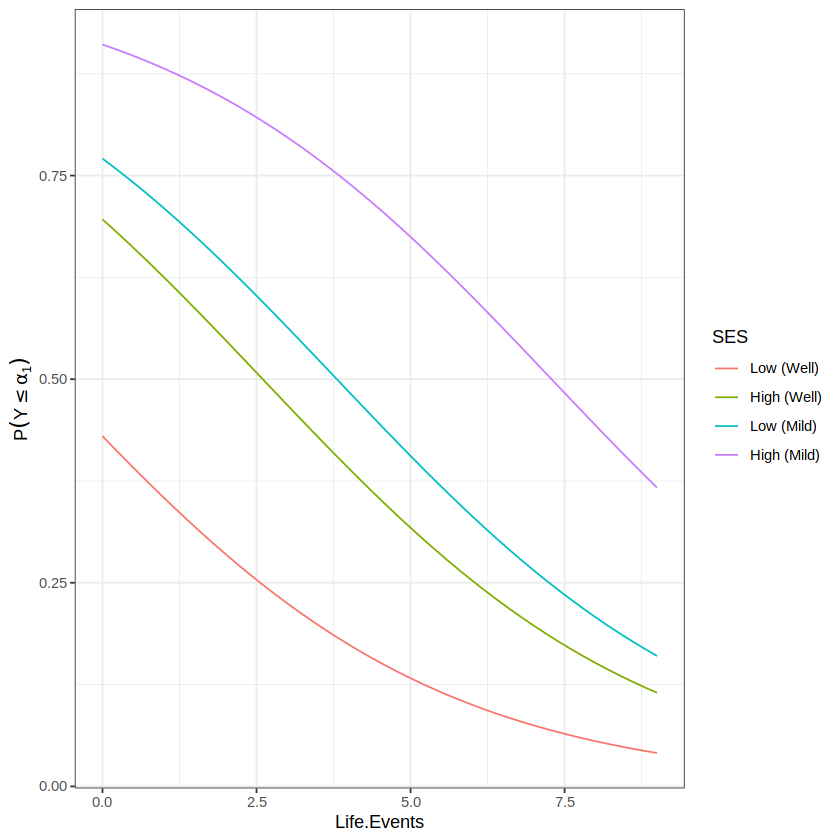

In [21]:
library(ggplot2)
library(latex2exp)
library(ggthemes)
library(wesanderson)

# for high
vX <- c()
vY  <- c()
group <- c()

# imp. level 1 (well)
x2 <- 1 # high
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- -0.2819 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 1)
}

x2 <- 0 # low
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- -0.2819 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 0)
}

# imp. level 2 (mild)
x2 <- 1 # high
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- 1.2129 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 3)
}

x2 <- 0 # low
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- 1.2129 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 2)
}




SES_LE_df <- data.frame(x=vX, y=vY, group=group)

ggplot() + 
  geom_line(data = SES_LE_df, aes(x, y, color = factor(group, levels=c(0,1,2,3), 
                                                       labels=c("Low (Well)", "High (Well)",
                                                                "Low (Mild)", "High (Mild)")
                                                      ))) +
  #theme_economist() +  scale_color_economist()+ 
 theme_bw() +
  labs(color="SES")+
  xlab("Life.Events") + ylab(TeX("$P(Y \\leq \\alpha_1)$")) +
    scale_fill_manual(values=wes_palette(n=3, name="BottleRocket2")) 

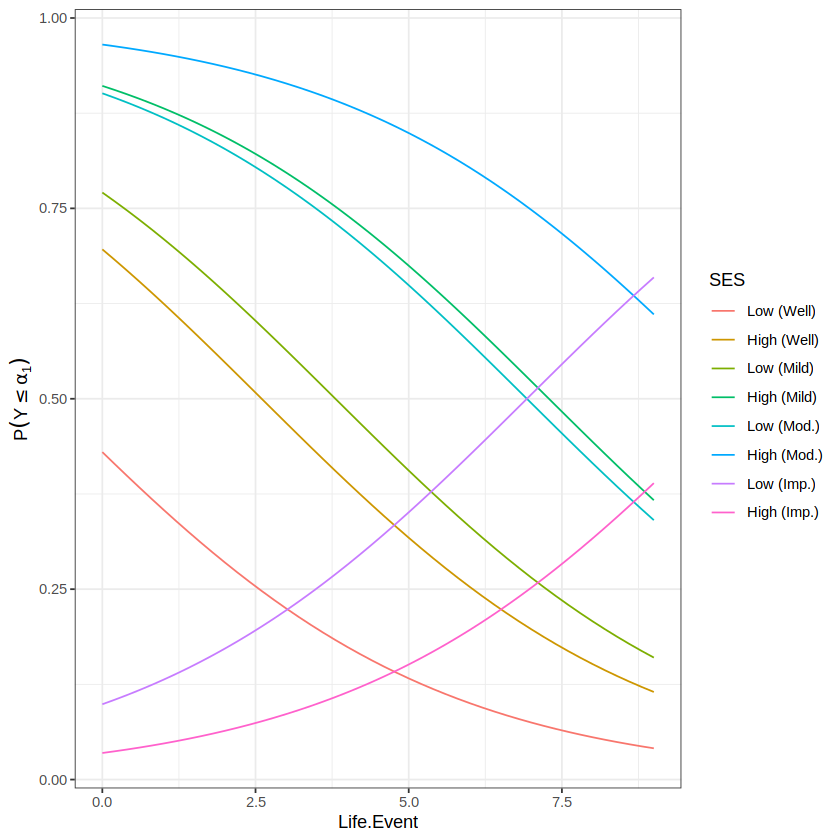

In [22]:
library(ggplot2)
library(latex2exp)
library(ggthemes)
library(wesanderson)

# for high
vX <- c()
vY  <- c()
group <- c()

# imp. level 1 (well)
x2 <- 1 # high
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- -0.2819 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 1)
}

x2 <- 0 # low
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- -0.2819 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 0)
}

# imp. level 2 (mild)
x2 <- 1 # high
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- 1.2129 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 3)
}

x2 <- 0 # low
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- 1.2129 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 2)
}

# imp. level 2 (moderate)
x2 <- 1 # high
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- 2.2095 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 5)
}

x2 <- 0 # low
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- 2.2095 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 4)
}


# imp. level 4
x2 <- 1 # high
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- 2.2095 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- 1- exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 7)
}

x2 <- 0 # low
for(i in seq(from = 0, to = 9, by = 0.2)){
    x1 <- i
    logit_val_y1 <- 2.2095 + (-0.3189*x1 + 1.1112*x2)
    P_y1 <- 1-exp(logit_val_y1)/(1+exp(logit_val_y1))
    #print(paste0(x1," / ", P_y1))
    vX <- c(vX, x1)
    vY <- c(vY, P_y1)
    group <- c(group, 6)
}


SES_LE_df <- data.frame(x=vX, y=vY, group=group)

ggplot() + 
  geom_line(data = SES_LE_df, aes(x, y, color = factor(group, levels=c(0,1,2,3,4,5,6,7), 
                                                       labels=c("Low (Well)", "High (Well)",
                                                                "Low (Mild)", "High (Mild)",
                                                                "Low (Mod.)", "High (Mod.)",
                                                               "Low (Imp.)", "High (Imp.)")
                                                      ))) +
  #theme_economist() +  scale_color_economist()+ 
 theme_bw() +
  labs(color="SES")+
  xlab("Life.Event") + ylab(TeX("$P(Y \\leq \\alpha_1)$")) +
    scale_fill_manual(values=wes_palette(n=3, name="BottleRocket2")) 

ajuste resultante con método `polr` de la librería **MASS**.

La librería **MASS** tiene el método ´polr´ para hacer regresión ordinal. La parametrización que plantea para la función lineal es distinta a la que usa ´vglm´ y consiste en $$logit(P(y_i\leq \alpha_j)=\alpha_j - \beta \mathbf{x}$$

In [24]:
m <- MASS::polr(Mental.Impairment ~ Life.Events + SES, data = mentalimp, Hess=TRUE)
summary(m)

Call:
MASS::polr(formula = Mental.Impairment ~ Life.Events + SES, data = mentalimp, 
    Hess = TRUE)

Coefficients:
              Value Std. Error t value
Life.Events  0.3189     0.1210   2.635
SEShigh     -1.1112     0.6109  -1.819

Intercepts:
                  Value   Std. Error t value
Well|Mild         -0.2819  0.6423    -0.4389
Mild|Moderate      1.2128  0.6607     1.8357
Moderate|Impaired  2.2094  0.7210     3.0644

Residual Deviance: 99.0979 
AIC: 109.0979 

```
Coefficients:
              Value Std. Error t value
Life.Events  0.3189     0.1210   2.635
SEShigh     -1.1112     0.6109  -1.819

Intercepts:
                  Value   Std. Error t value
Well|Mild         -0.2819  0.6423    -0.4389
Mild|Moderate      1.2128  0.6607     1.8357
Moderate|Impaired  2.2094  0.7210     3.0644
```


In [25]:
print(xtable(coef(summary(m)), digits = 4))

% latex table generated in R 4.2.2 by xtable 1.8-4 package
% Sun May 28 22:59:50 2023
\begin{table}[ht]
\centering
\begin{tabular}{rrrr}
  \hline
 & Value & Std. Error & t value \\ 
  \hline
Life.Events & 0.3189 & 0.1210 & 2.6354 \\ 
  SEShigh & -1.1112 & 0.6109 & -1.8191 \\ 
  Well$|$Mild & -0.2819 & 0.6423 & -0.4389 \\ 
  Mild$|$Moderate & 1.2128 & 0.6607 & 1.8357 \\ 
  Moderate$|$Impaired & 2.2094 & 0.7210 & 3.0644 \\ 
   \hline
\end{tabular}
\end{table}


**Observaciones**

* Interceptos tienen igual signo.
* Coeficientes con mismo valor pero distinto signo.

- `polr` implementa el modelo con parámetros: $Logit(\widehat{P}(y_i\leq j))=\widehat{\alpha}_j - \beta X$
- `vglm` implementa el modeo  con parámetros: $Logit(\widehat{P}(y_i\leq j))=\widehat{\alpha}_j \mathbf{+} \beta X$

### Comparación de ajuste desde **tabla** con `vglm` vs **casos** usando `vglm`/`polr`

**Transformacion** a tabla (quitando columna de Life.Events)

In [26]:
mentalimp_tab <- mentalimp %>% select(Mental.Impairment, SES, Life.Events) %>% 
    count(Mental.Impairment, SES, sort = TRUE) %>%
    pivot_wider(names_from = Mental.Impairment, values_from = n)

mentalimp_tab

SES,Well,Mild,Moderate,Impaired
<fct>,<int>,<int>,<int>,<int>
high,8,8,2,4
low,4,4,5,5


In [27]:
# ajustamos primero modelo con la data en formato de filas y columans
fit_mimpA <- vglm(Mental.Impairment ~ SES, 
                 family=cumulative(link = "logitlink", 
                 parallel=TRUE, reverse=FALSE), 
                 data=mentalimp)
summary(fit_mimpA)


Call:
vglm(formula = Mental.Impairment ~ SES, family = cumulative(link = "logitlink", 
    parallel = TRUE, reverse = FALSE), data = mentalimp)

Coefficients: 
              Estimate Std. Error z value Pr(>|z|)   
(Intercept):1 -1.36376    0.49897  -2.733  0.00627 **
(Intercept):2 -0.04172    0.44695  -0.093  0.92563   
(Intercept):3  0.83061    0.47232   1.759  0.07865 . 
SEShigh        0.85534    0.58425   1.464  0.14319   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Names of linear predictors: logitlink(P[Y<=1]), logitlink(P[Y<=2]), 
logitlink(P[Y<=3])

Residual deviance: 106.8744 on 116 degrees of freedom

Log-likelihood: -53.4372 on 116 degrees of freedom

Number of Fisher scoring iterations: 4 

No Hauck-Donner effect found in any of the estimates


Exponentiated coefficients:
SEShigh 
2.35217 

In [28]:
m <- MASS::polr(Mental.Impairment ~ SES, data = mentalimp, Hess=TRUE)
summary(m)

Call:
MASS::polr(formula = Mental.Impairment ~ SES, data = mentalimp, 
    Hess = TRUE)

Coefficients:
          Value Std. Error t value
SEShigh -0.8553     0.5865  -1.458

Intercepts:
                  Value   Std. Error t value
Well|Mild         -1.3638  0.5038    -2.7070
Mild|Moderate     -0.0417  0.4448    -0.0938
Moderate|Impaired  0.8306  0.4659     1.7827

Residual Deviance: 106.8744 
AIC: 114.8744 

Ahora en formato de **Tabla**:

In [29]:
str(knee_tab)

tibble [2 × 6] (S3: tbl_df/tbl/data.frame)
 $ Th: Factor w/ 2 levels "P","T": 1 2
 $ d1: int [1:2] 17 19
 $ d2: int [1:2] 8 26
 $ d3: int [1:2] 14 11
 $ d4: int [1:2] 20 6
 $ d5: int [1:2] 4 2


In [30]:
str(mentalimp_tab)

tibble [2 × 5] (S3: tbl_df/tbl/data.frame)
 $ SES     : Factor w/ 2 levels "low","high": 2 1
 $ Well    : int [1:2] 8 4
 $ Mild    : int [1:2] 8 4
 $ Moderate: int [1:2] 2 5
 $ Impaired: int [1:2] 4 5


In [31]:
# Ahora en formato tabla
fit_mimpB <- vglm(cbind(Well, Mild, Moderate, Impaired) ~ SES, 
                 family=cumulative(link = "logitlink", parallel=TRUE, reverse=FALSE), 
                 data=mentalimp_tab)
summary(fit_mimpB)


Call:
vglm(formula = cbind(Well, Mild, Moderate, Impaired) ~ SES, family = cumulative(link = "logitlink", 
    parallel = TRUE, reverse = FALSE), data = mentalimp_tab)

Coefficients: 
              Estimate Std. Error z value Pr(>|z|)   
(Intercept):1 -1.36377    0.49899  -2.733  0.00627 **
(Intercept):2 -0.04172    0.44695  -0.093  0.92562   
(Intercept):3  0.83061    0.47233   1.759  0.07866 . 
SEShigh        0.85535    0.58425   1.464  0.14319   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Names of linear predictors: logitlink(P[Y<=1]), logitlink(P[Y<=2]), 
logitlink(P[Y<=3])

Residual deviance: 1.5896 on 2 degrees of freedom

Log-likelihood: -9.582 on 2 degrees of freedom

Number of Fisher scoring iterations: 5 

No Hauck-Donner effect found in any of the estimates


Exponentiated coefficients:
 SEShigh 
2.352195 